## 1. Import required libraries


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

In [5]:
import warnings
warnings.filterwarnings("ignore")


## 2. Load dataset

In [7]:
data = pd.read_csv(
    "https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1003-CustTransPred.zip"
)

In [9]:
data

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199995,train_199995,0,11.4880,-0.4956,8.2622,3.5142,10.3404,11.6081,5.6709,15.1516,...,6.1415,13.2305,3.9901,0.9388,18.0249,-1.7939,2.1661,8.5326,16.6660,-17.8661
199996,train_199996,0,4.9149,-2.4484,16.7052,6.6345,8.3096,-10.5628,5.8802,21.5940,...,4.9611,4.6549,0.6998,1.8341,22.2717,1.7337,-2.1651,6.7419,15.9054,0.3388
199997,train_199997,0,11.2232,-5.0518,10.5127,5.6456,9.3410,-5.4086,4.5555,21.5571,...,4.0651,5.4414,3.1032,4.8793,23.5311,-1.5736,1.2832,8.7155,13.8329,4.1995
199998,train_199998,0,9.7148,-8.6098,13.6104,5.7930,12.5173,0.5339,6.0479,17.0152,...,2.6840,8.6587,2.7337,11.1178,20.4158,-0.0786,6.7980,10.0342,15.5289,-13.9001


In [11]:
print("Dataset Shape:", data.shape)

Dataset Shape: (200000, 202)


## 3. Basic dataset inspection

In [13]:
print("\nFirst 5 Records:")
display(data.head())


First 5 Records:


,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104


In [15]:
print("\nDataset Information:")
data.info()



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Columns: 202 entries, ID_code to var_199
dtypes: float64(200), int64(1), object(1)
memory usage: 308.2+ MB


## 4. Check missing values


In [17]:
print("\nTotal Missing Values:")
print(data.isnull().sum().sum())


Total Missing Values:
0


## 5. Check duplicate records


In [19]:
print("\nDuplicate Rows:")
print(data.duplicated().sum())


Duplicate Rows:
0


## 6. Check target distribution

In [21]:
print("\nTarget Distribution:")
print(data["target"].value_counts())



Target Distribution:
target
0    179902
1     20098
Name: count, dtype: int64


In [23]:
print("\nTarget Percentage:")
print(
    data["target"].value_counts(normalize=True) * 100
)


Target Percentage:
target
0    89.951
1    10.049
Name: proportion, dtype: float64


## 7. Separate features and target

In [36]:
X = data.drop(columns=["ID_code", "target"])
y = data["target"]

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)


Feature Shape: (200000, 200)
Target Shape: (200000,)


## 8. Target variable distribution

In [39]:
target_counts = data["target"].value_counts().sort_index()

In [41]:
target_percentages = data["target"].value_counts(
    normalize=True
).sort_index() * 100

In [43]:
target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages
})

print("Target Variable Distribution:")
display(target_summary)

Target Variable Distribution:


,Count,Percentage
target,,
0,179902,89.951
1,20098,10.049


## 9. Visualise the distribution

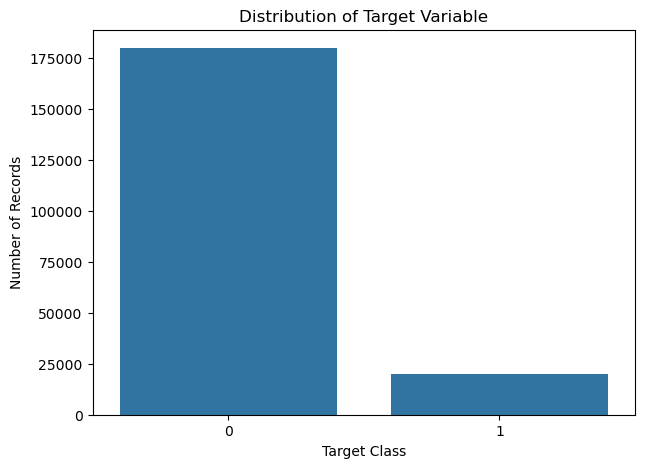

In [46]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=data,
    x="target"
)

plt.title("Distribution of Target Variable")
plt.xlabel("Target Class")
plt.ylabel("Number of Records")
plt.show()


## 10. Statistical summary of predictor variables

In [49]:
features = data.drop(columns=["ID_code", "target"])

In [51]:
feature_summary = features.describe().T

display(feature_summary)


,count,mean,std,min,25%,50%,75%,max
var_0,200000.0,10.679914,3.040051,0.4084,8.453850,10.52475,12.758200,20.3150
var_1,200000.0,-1.627622,4.050044,-15.0434,-4.740025,-1.60805,1.358625,10.3768
var_2,200000.0,10.715192,2.640894,2.1171,8.722475,10.58000,12.516700,19.3530
var_3,200000.0,6.796529,2.043319,-0.0402,5.254075,6.82500,8.324100,13.1883
var_4,200000.0,11.078333,1.623150,5.0748,9.883175,11.10825,12.261125,16.6714
...,...,...,...,...,...,...,...,...
var_195,200000.0,-0.142088,1.429372,-5.2610,-1.170700,-0.17270,0.829600,4.2729
var_196,200000.0,2.303335,5.454369,-14.2096,-1.946925,2.40890,6.556725,18.3215
var_197,200000.0,8.908158,0.921625,5.9606,8.252800,8.88820,9.593300,12.0004
var_198,200000.0,15.870720,3.010945,6.2993,13.829700,15.93405,18.064725,26.0791


In [53]:
print("\nFeature Data Types:")
print(features.dtypes.value_counts())



Feature Data Types:
float64    200
Name: count, dtype: int64


In [55]:
# Check for constant columns
constant_columns = [
    col for col in features.columns
    if features[col].nunique() <= 1
]

In [57]:
print("\nNumber of Constant Columns:", len(constant_columns))
print("Constant Columns:", constant_columns)



Number of Constant Columns: 0
Constant Columns: []


In [59]:
sample_features = [
    "var_0", "var_1", "var_2", "var_3", "var_4"
]


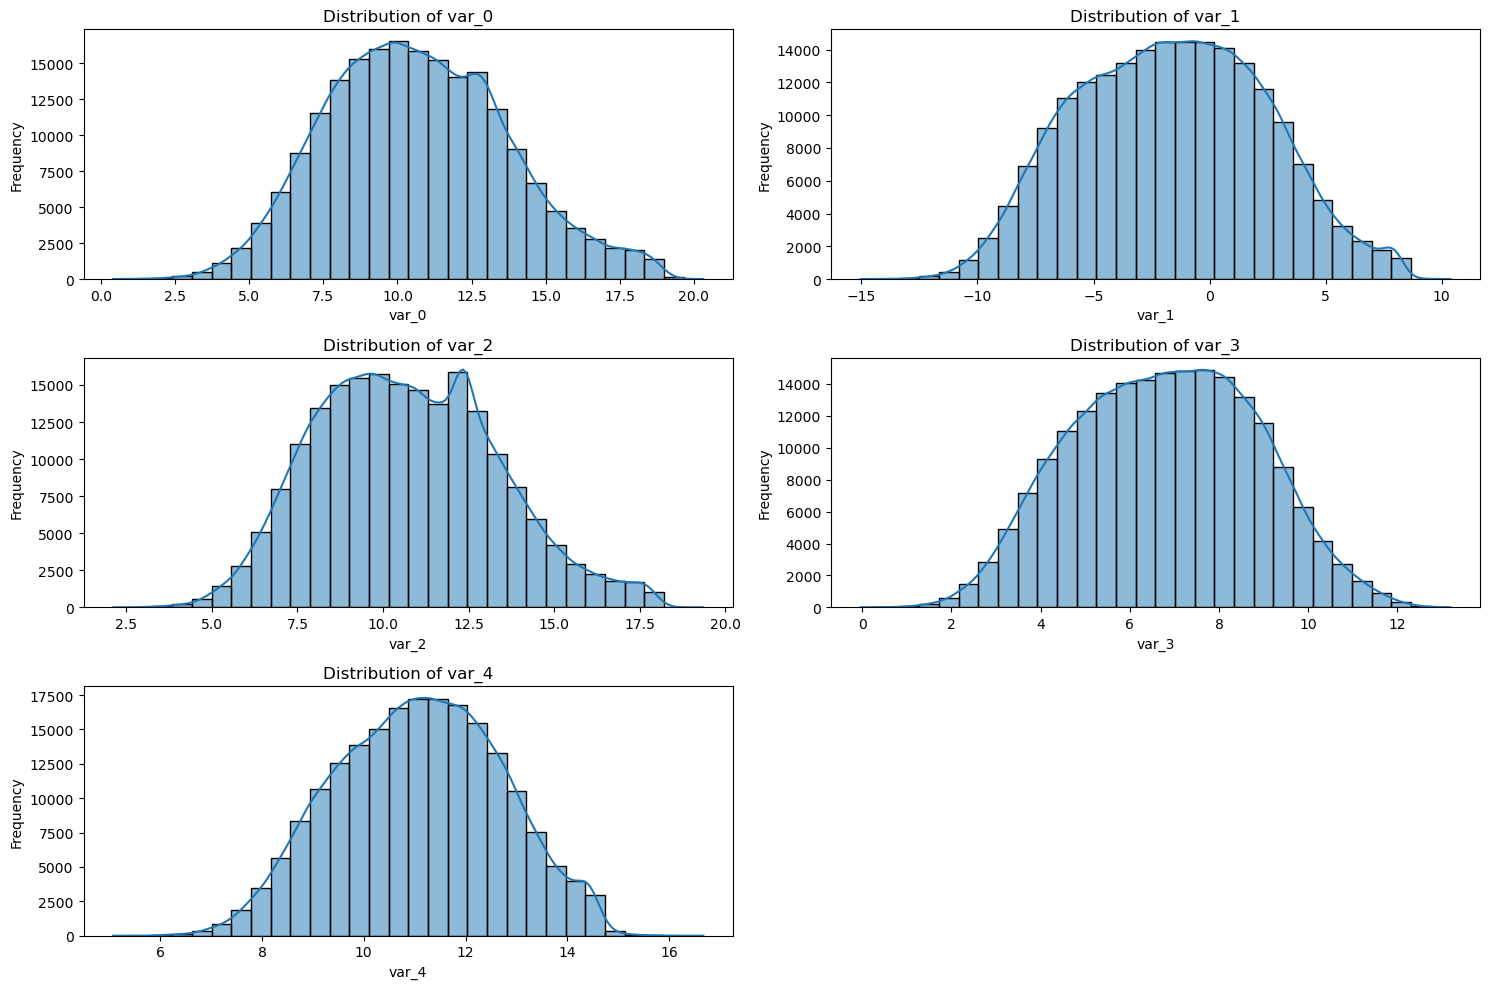

In [61]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(sample_features, 1):
    plt.subplot(3, 2, i)
    sns.histplot(features[col], kde=True, bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


In [63]:
# Calculate skewness
print("\nFeature Skewness:")
display(features[sample_features].skew().to_frame("Skewness"))


Feature Skewness:


,Skewness
var_0,0.235639
var_1,0.053115
var_2,0.260313
var_3,-0.003548
var_4,-0.048210


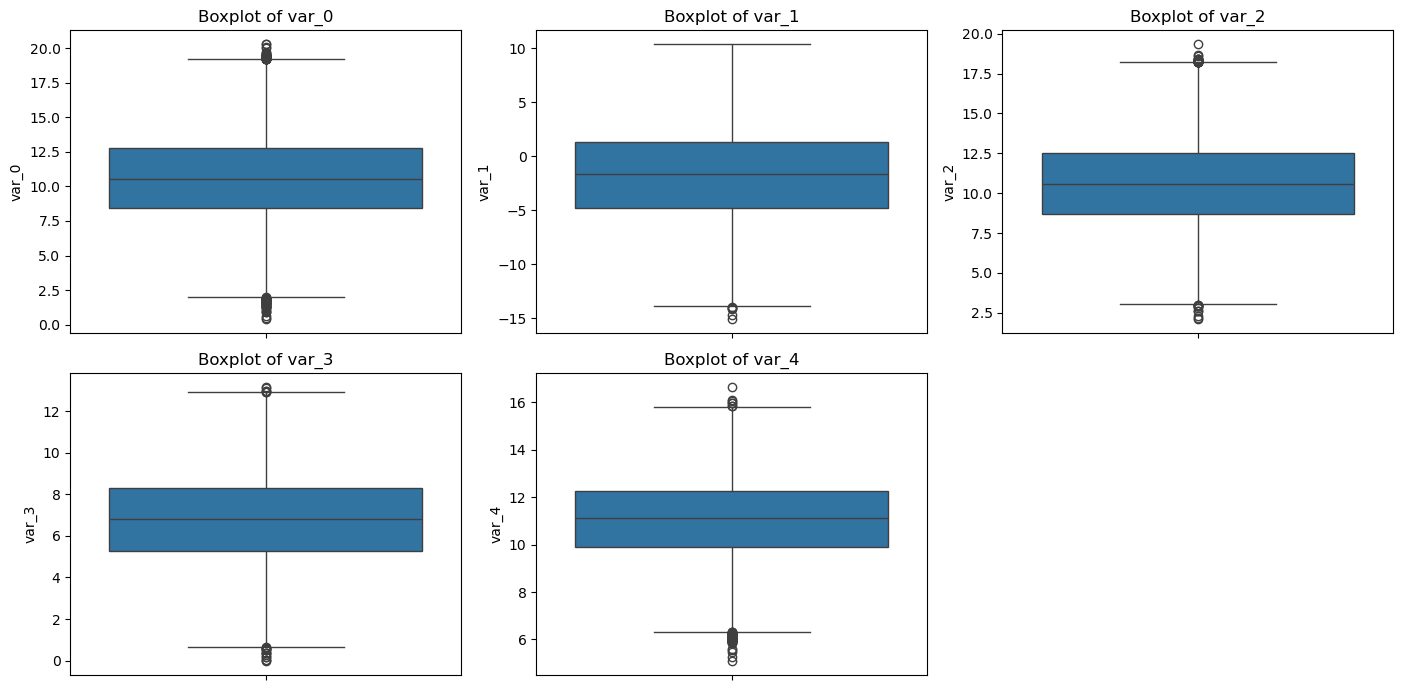

In [65]:
# Visualise potential outliers
plt.figure(figsize=(14, 7))

for i, col in enumerate(sample_features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=features[col])
    plt.title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

In [67]:
# Calculate IQR-based outlier counts
outlier_summary = []

for col in sample_features:
    Q1 = features[col].quantile(0.25)
    Q3 = features[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (features[col] < lower) |
        (features[col] > upper)
    ).sum()

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": count
    })

display(pd.DataFrame(outlier_summary))


,Feature,Lower Bound,Upper Bound,Outlier Count
0,var_0,1.997325,19.214725,104
1,var_1,-13.888000,10.506600,6
2,var_2,3.031137,18.208038,49
3,var_3,0.649038,12.929137,22
4,var_4,6.316250,15.828050,76


## 11. Correlation analysis

In [70]:
correlation_matrix = features.corr()


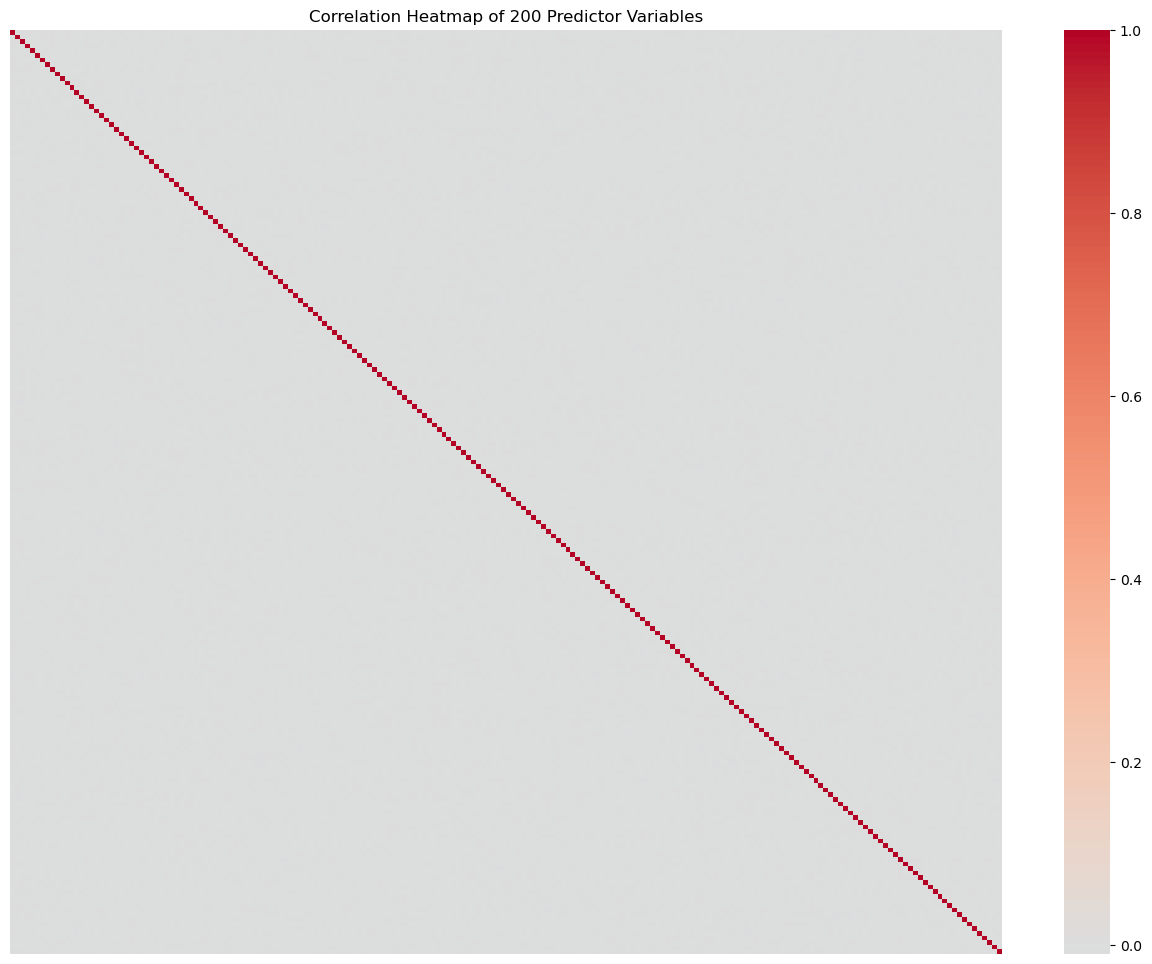

In [72]:
# Display correlation heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0,
    xticklabels=False,
    yticklabels=False
)

plt.title("Correlation Heatmap of 200 Predictor Variables")
plt.show()

In [74]:
# Find highly correlated feature pairs
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

high_correlations = (
    upper_triangle.stack()
    .reset_index()
)

high_correlations.columns = [
    "Feature 1", "Feature 2", "Correlation"
]

high_correlations = high_correlations[
    high_correlations["Correlation"].abs() > 0.80
].sort_values(
    by="Correlation",
    key=abs,
    ascending=False
)

print("Highly Correlated Feature Pairs (|correlation| > 0.80):")
display(high_correlations)

print(
    "\nNumber of highly correlated pairs:",
    len(high_correlations)
)


Highly Correlated Feature Pairs (|correlation| > 0.80):


,Feature 1,Feature 2,Correlation



Number of highly correlated pairs: 0


## 12. Check feature relationships with the target

In [77]:
correlation_with_target = data.drop(
    columns=["ID_code"]
).corr()["target"].drop("target")

In [79]:
# Sort by absolute correlation
top_correlations = correlation_with_target.abs().sort_values(
    ascending=False
).head(15)

In [81]:
# Display actual correlation values
top_correlations = correlation_with_target.loc[
    top_correlations.index
]

print("Top 15 Features Correlated with Target:")
display(
    top_correlations.to_frame(
        name="Correlation with Target"
    )
)

Top 15 Features Correlated with Target:


,Correlation with Target
var_81,-0.080917
var_139,-0.074080
var_12,-0.069489
var_6,0.066731
var_110,0.064275
var_146,-0.063644
var_53,0.063399
var_26,0.062422
var_76,-0.061917
var_174,-0.061669


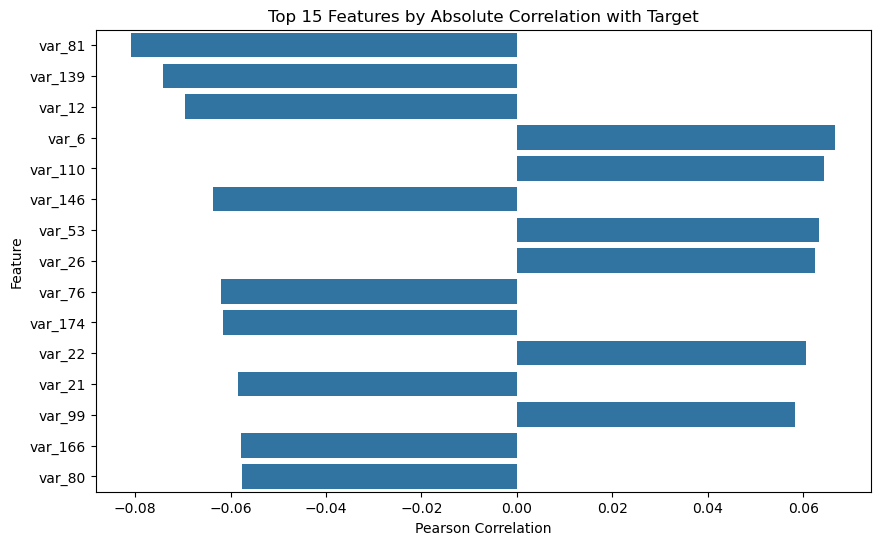

In [83]:
# Visualise the top 15 correlations
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_correlations.values,
    y=top_correlations.index
)

plt.title("Top 15 Features by Absolute Correlation with Target")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.show()



## Exploratory Data Analysis (EDA)

### 1. Dataset Overview
- Total records: 200,000
- Predictor variables: 200
- Missing values: 0
- Duplicate records: 0
- Constant features: 0

### 2. Target Distribution
- Class 0: 179,902 (89.951%)
- Class 1: 20,098 (10.049%)

The dataset exhibits class imbalance, which makes
accuracy alone an insufficient evaluation metric.

### 3. Feature Analysis
- All 200 predictor variables are numerical.
- Five sample features showed low skewness.
- Potential outliers were identified using the IQR method.
- No highly correlated feature pairs were found
  using an absolute correlation threshold of 0.80.

### 4. Feature-Target Relationships
The top 15 individual Pearson correlations with
the target were weak (absolute values below 0.09).

### 5. EDA Conclusion
The dataset contains numerical predictors, class
imbalance, and potential outliers. Features will
be retained for subsequent preprocessing and
model evaluation.


# Data Preprocessing

In [88]:
# Separate independent variables and target variable

X = data.drop(columns=["ID_code", "target"])
y = data["target"]

print("Feature Matrix Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())


Feature Matrix Shape: (200000, 200)
Target Variable Shape: (200000,)

Target Distribution:
target
0    179902
1     20098
Name: count, dtype: int64


In [90]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check dataset dimensions
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True) * 100)


Training Features: (160000, 200)
Testing Features: (40000, 200)

Training Target Distribution:
target
0    89.95125
1    10.04875
Name: proportion, dtype: float64

Testing Target Distribution:
target
0    89.95
1    10.05
Name: proportion, dtype: float64


In [92]:

from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
scaler = StandardScaler()

# Fit scaler only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using training statistics
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrames to preserve column names
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

# Verify scaling
print("Training Data - Feature Means:")
print(X_train_scaled.mean().head())

print("\nTraining Data - Feature Standard Deviations:")
print(X_train_scaled.std().head())

print("\nScaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)


Training Data - Feature Means:
var_0    5.189071e-16
var_1   -7.229772e-17
var_2   -4.098055e-16
var_3    9.857448e-16
var_4   -3.723244e-16
dtype: float64

Training Data - Feature Standard Deviations:
var_0    1.000003
var_1    1.000003
var_2    1.000003
var_3    1.000003
var_4    1.000003
dtype: float64

Scaled Training Shape: (160000, 200)
Scaled Testing Shape: (40000, 200)


In [94]:

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Calculate balanced class weights
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class Weights:")
print(class_weights)

print("\nTraining Class Distribution:")
print(y_train.value_counts())


Class Weights:
{0: 0.5558566445713651, 1: 4.975743251648215}

Training Class Distribution:
target
0    143922
1     16078
Name: count, dtype: int64


In [96]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Initialize Logistic Regression
lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train model
lr_model.fit(X_train_scaled, y_train)

# Generate predictions
y_pred_lr = lr_model.predict(X_test_scaled)

# Predict probabilities for ROC-AUC
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

# Evaluate model
print("Logistic Regression - Balanced Class Weights")
print("---------------------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))


Logistic Regression - Balanced Class Weights
---------------------------------------------
Accuracy: 0.7834
Precision: 0.2865416436845008
Recall: 0.7753731343283582
F1 Score: 0.4184454289166331
ROC-AUC: 0.8598998891036755

Confusion Matrix:
[[28219  7761]
 [  903  3117]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.78      0.87     35980
           1       0.29      0.78      0.42      4020

    accuracy                           0.78     40000
   macro avg       0.63      0.78      0.64     40000
weighted avg       0.90      0.78      0.82     40000



In [98]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Split the existing training data
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Create a leakage-safe pipeline
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train using only the fitting subset
lr_pipeline.fit(X_fit, y_fit)

# Obtain validation probabilities
y_val_prob = lr_pipeline.predict_proba(X_val)[:, 1]

print("Training subset:", X_fit.shape)
print("Validation subset:", X_val.shape)
print("Validation positive cases:", y_val.sum())


Training subset: (128000, 200)
Validation subset: (32000, 200)
Validation positive cases: 3216


In [100]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, y_val_pred, zero_division=0),
        "Recall": recall_score(y_val, y_val_pred, zero_division=0),
        "F1 Score": f1_score(y_val, y_val_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1 Score
0,0.3,0.1943,0.9002,0.3196
1,0.4,0.2319,0.8399,0.3635
2,0.5,0.2794,0.7705,0.4101
3,0.6,0.3376,0.6894,0.4533
4,0.7,0.4139,0.5886,0.4860


### Threshold Tuning

Different classification thresholds were evaluated using the validation dataset.

Key observations:
- Increasing the threshold improved precision.
- Recall decreased as the threshold increased.
- The threshold of 0.70 achieved the highest F1 score (0.4860).
- A threshold of 0.70 was selected provisionally for final model evaluation.

Threshold selection was performed using the validation dataset to avoid test-data leakage.

## Final Logistic Regression Model

In [104]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create final model pipeline
final_lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train using the complete training dataset
final_lr_model.fit(X_train, y_train)

# Predict probabilities on the test dataset
y_test_prob = final_lr_model.predict_proba(X_test)[:, 1]

# Apply the selected threshold
selected_threshold = 0.70
y_test_pred = (y_test_prob >= selected_threshold).astype(int)

print("Final model training completed!")
print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Selected threshold:", selected_threshold)

Final model training completed!
Training records: 160000
Testing records: 40000
Selected threshold: 0.7


In [106]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1 Score:", f1_score(y_test, y_test_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

Accuracy: 0.87825
Precision: 0.42227505486466715
Recall: 0.5743781094527363
F1 Score: 0.4867200674536256
ROC-AUC: 0.8598998891036755

Confusion Matrix:
[[32821  3159]
 [ 1711  2309]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.91      0.93     35980
           1       0.42      0.57      0.49      4020

    accuracy                           0.88     40000
   macro avg       0.69      0.74      0.71     40000
weighted avg       0.90      0.88      0.89     40000



### Final Logistic Regression Model – Performance Summary

The final Logistic Regression model was trained using 160,000 training records and evaluated on 40,000 unseen test records.

A class-weighted Logistic Regression model was implemented using a StandardScaler pipeline to handle feature scaling and class imbalance.

A classification threshold of 0.70 was selected based on validation results.

**Test Performance:**

| Metric | Score |
|---|---:|
| Accuracy | 87.83% |
| Precision | 42.23% |
| Recall | 57.44% |
| F1 Score | 48.67% |
| ROC-AUC | 85.99% |

**Key Observations:**
- The model correctly identified 2,309 out of 4,020 positive cases.
- It achieved 57.44% recall for the minority class.
- False positives remain relatively high at 3,159.
- Class weighting improved the model's ability to identify minority-class cases, with a trade-off in precision and accuracy.

**Conclusion:**

The model demonstrates useful classification capability despite the imbalanced dataset. Further experimentation with alternative algorithms and hyperparameter tuning may improve minority-class prediction performance.

# Model Building and Evaluation

## Decision Tree Classifier

In [111]:
from sklearn.tree import DecisionTreeClassifier

# Initialize Decision Tree
dt_model = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

# Train model
dt_model.fit(X_train, y_train)

# Predict probabilities
y_test_prob_dt = dt_model.predict_proba(X_test)[:, 1]

# Apply the same threshold
y_test_pred_dt = (y_test_prob_dt >= 0.70).astype(int)

print("Decision Tree training completed!")

Decision Tree training completed!


In [113]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_test_pred_dt))
print("Precision:", precision_score(y_test, y_test_pred_dt, zero_division=0))
print("Recall:", recall_score(y_test, y_test_pred_dt, zero_division=0))
print("F1 Score:", f1_score(y_test, y_test_pred_dt, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_dt))

Accuracy: 0.837
Precision: 0.22085752568110764
Recall: 0.24601990049751243
F1 Score: 0.23276064956460343
ROC-AUC: 0.638951438610173

Confusion Matrix:
[[32491  3489]
 [ 3031   989]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.90      0.91     35980
           1       0.22      0.25      0.23      4020

    accuracy                           0.84     40000
   macro avg       0.57      0.57      0.57     40000
weighted avg       0.84      0.84      0.84     40000



### Decision Tree Classifier – Performance Summary

A Decision Tree Classifier was trained using class weighting to address the imbalanced target distribution.

**Model Configuration:**
- Maximum depth: 10
- Minimum samples split: 20
- Minimum samples leaf: 10
- Class weight: Balanced
- Classification threshold: 0.70

**Test Performance:**

| Metric | Score |
|---|---:|
| Accuracy | 83.70% |
| Precision | 22.09% |
| Recall | 24.60% |
| F1 Score | 23.28% |
| ROC-AUC | 63.90% |

**Key Observations:**
- The model identified 989 positive cases correctly.
- It missed 3,031 actual positive cases.
- Minority-class recall and F1 score were considerably lower than those of Logistic Regression.
- The current tree configuration may require further hyperparameter tuning.

**Conclusion:**

Under the current configuration and classification threshold, the Decision Tree performed worse than Logistic Regression. Further tuning may improve its predictive performance.

## Random Forest Classifier

In [117]:
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Predict probabilities
y_test_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Apply the same classification threshold
y_test_pred_rf = (y_test_prob_rf >= 0.70).astype(int)

print("Random Forest training completed!")

Random Forest training completed!


In [119]:
print("Accuracy:", accuracy_score(y_test, y_test_pred_rf))
print("Precision:", precision_score(y_test, y_test_pred_rf, zero_division=0))
print("Recall:", recall_score(y_test, y_test_pred_rf, zero_division=0))
print("F1 Score:", f1_score(y_test, y_test_pred_rf, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_rf))

Accuracy: 0.8995
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC-AUC: 0.8205976095066634

Confusion Matrix:
[[35980     0]
 [ 4020     0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      1.00      0.95     35980
           1       0.00      0.00      0.00      4020

    accuracy                           0.90     40000
   macro avg       0.45      0.50      0.47     40000
weighted avg       0.81      0.90      0.85     40000



In [121]:
# Train a separate Random Forest for validation
rf_validation_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_validation_model.fit(X_fit, y_fit)

# Get validation probabilities
y_val_prob_rf = rf_validation_model.predict_proba(X_val)[:, 1]

print("Validation ROC-AUC:",
      roc_auc_score(y_val, y_val_prob_rf))

print("Minimum probability:", y_val_prob_rf.min())
print("Maximum probability:", y_val_prob_rf.max())

Validation ROC-AUC: 0.8257298766209255
Minimum probability: 0.20741673211918701
Maximum probability: 0.5975921575856534


In [123]:
threshold_results_rf = []

for threshold in [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
    y_val_pred_rf = (y_val_prob_rf >= threshold).astype(int)

    threshold_results_rf.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_val_pred_rf, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_val_pred_rf, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, y_val_pred_rf, zero_division=0
        )
    })

display(pd.DataFrame(threshold_results_rf).round(4))

,Threshold,Precision,Recall,F1 Score
0,0.1,0.1005,1.0000,0.1826
1,0.2,0.1005,1.0000,0.1826
2,0.3,0.1351,0.9627,0.2370
3,0.4,0.3953,0.4745,0.4313
4,0.5,0.7803,0.0420,0.0797
5,0.6,0.0000,0.0000,0.0000
6,0.7,0.0000,0.0000,0.0000


### Random Forest – Threshold Tuning

The Random Forest model was evaluated using multiple classification thresholds on the validation dataset.

**Key Observations:**
- Lower thresholds resulted in higher recall but lower precision.
- Higher thresholds significantly reduced recall.
- A threshold of 0.40 achieved the highest F1 score among the tested values.

**Selected Threshold:** 0.40

**Best Validation F1 Score:** 0.4313

The threshold was selected using validation data to avoid tuning against the test dataset.

In [125]:
# Apply validation-selected threshold
selected_threshold_rf = 0.40

y_test_pred_rf_tuned = (
    y_test_prob_rf >= selected_threshold_rf
).astype(int)

print("Random Forest – Tuned Threshold:", selected_threshold_rf)

print("Accuracy:", accuracy_score(y_test, y_test_pred_rf_tuned))
print("Precision:", precision_score(y_test, y_test_pred_rf_tuned, zero_division=0))
print("Recall:", recall_score(y_test, y_test_pred_rf_tuned, zero_division=0))
print("F1 Score:", f1_score(y_test, y_test_pred_rf_tuned, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_rf_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_rf_tuned))

Random Forest – Tuned Threshold: 0.4
Accuracy: 0.848925
Precision: 0.3422735069390301
Recall: 0.5460199004975125
F1 Score: 0.4207802166203393
ROC-AUC: 0.8205976095066634

Confusion Matrix:
[[31762  4218]
 [ 1825  2195]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.88      0.91     35980
           1       0.34      0.55      0.42      4020

    accuracy                           0.85     40000
   macro avg       0.64      0.71      0.67     40000
weighted avg       0.89      0.85      0.86     40000



### Random Forest Classifier – Performance Summary

A Random Forest Classifier with 200 decision trees was trained using class weighting to address class imbalance.

**Model Configuration:**
- Number of trees: 200
- Maximum depth: 15
- Minimum samples split: 20
- Minimum samples leaf: 10
- Class weight: Balanced
- Selected classification threshold: 0.40

**Test Performance:**

| Metric | Score |
|---|---:|
| Accuracy | 84.89% |
| Precision | 34.23% |
| Recall | 54.60% |
| F1 Score | 42.08% |
| ROC-AUC | 82.06% |

**Key Observations:**
- The model correctly identified 2,195 positive cases.
- It missed 1,825 actual positive cases.
- Threshold tuning improved minority-class detection compared with the initial 0.70 threshold.
- The model still produced 4,218 false positives.

**Conclusion:**

The tuned Random Forest achieved a reasonable balance between precision and recall. Its performance was better than the current Decision Tree configuration but lower than Logistic Regression on the selected test metrics.

## Model Performance Comparison

The three classification algorithms were evaluated on the same test dataset containing 40,000 records.

### Performance Metrics

| Metric | Logistic Regression | Decision Tree | Random Forest |
|---|---:|---:|---:|
| Accuracy | **87.83%** | 83.70% | 84.89% |
| Precision | **42.23%** | 22.09% | 34.23% |
| Recall | **57.44%** | 24.60% | 54.60% |
| F1 Score | **48.67%** | 23.28% | 42.08% |
| ROC-AUC | **85.99%** | 63.90% | 82.06% |
| Classification Threshold | 0.70 | 0.70 | 0.40 |

### Model Comparison and Observations

1. **Logistic Regression:** Achieved the highest accuracy, precision, recall, F1 score and ROC-AUC among the three evaluated models.
2. **Decision Tree:** Delivered the weakest performance, particularly in identifying minority-class records.
3. **Random Forest:** Improved minority-class detection compared with the Decision Tree and achieved a competitive recall of 54.60%.

### Overall Conclusion

Logistic Regression performed best among the three models under the current configurations and validation-selected thresholds.

It achieved an F1 score of 48.67% and ROC-AUC of 85.99%, making it the current preferred model

## Model Performance Visualization

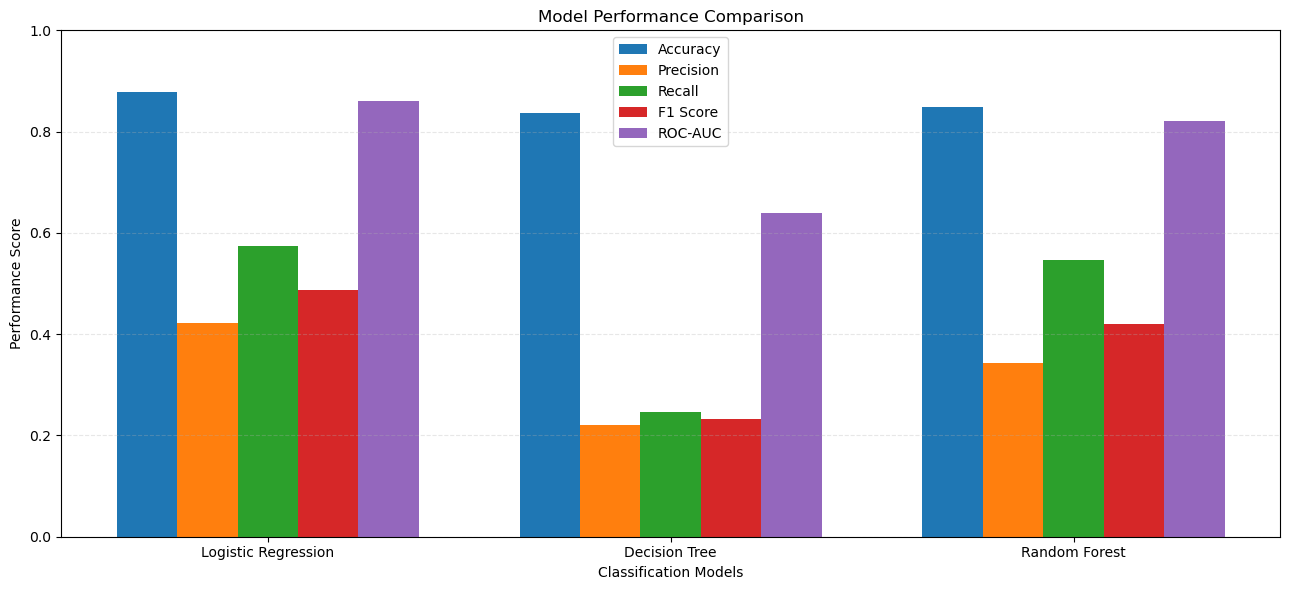

In [132]:
import matplotlib.pyplot as plt
import numpy as np

models = ['Logistic Regression', 'Decision Tree', 'Random Forest']

accuracy = [0.8783, 0.8370, 0.8489]
precision = [0.4223, 0.2209, 0.3423]
recall = [0.5744, 0.2460, 0.5460]
f1_score_values = [0.4867, 0.2328, 0.4208]
roc_auc = [0.8599, 0.6390, 0.8206]

x = np.arange(len(models))
width = 0.15

plt.figure(figsize=(13, 6))

plt.bar(x - 2*width, accuracy, width, label='Accuracy')
plt.bar(x - width, precision, width, label='Precision')
plt.bar(x, recall, width, label='Recall')
plt.bar(x + width, f1_score_values, width, label='F1 Score')
plt.bar(x + 2*width, roc_auc, width, label='ROC-AUC')

plt.xlabel('Classification Models')
plt.ylabel('Performance Score')
plt.title('Model Performance Comparison')
plt.xticks(x, models)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

## Confusion Matrix Comparison

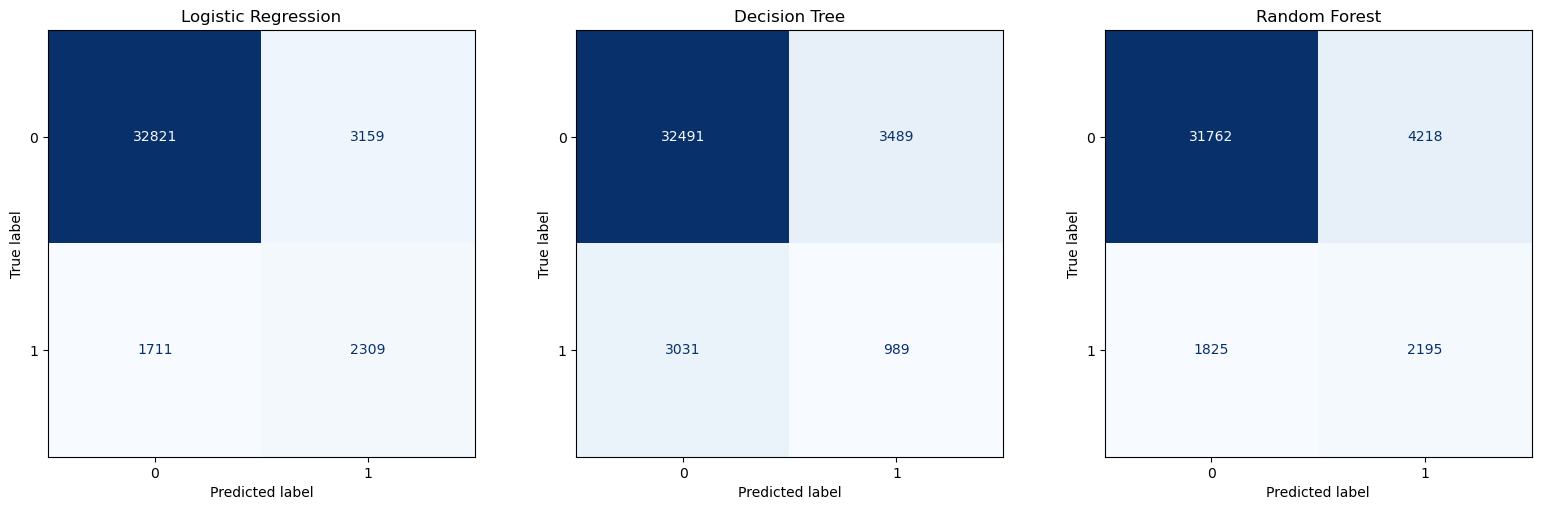

In [135]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred,
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred_dt,
    ax=axes[1],
    cmap="Blues",
    colorbar=False
)
axes[1].set_title("Decision Tree")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred_rf_tuned,
    ax=axes[2],
    cmap="Blues",
    colorbar=False
)
axes[2].set_title("Random Forest")

plt.tight_layout()
plt.show()

## Final Conclusion

This project focused on predicting customer transaction outcomes using machine learning classification techniques.

The dataset contained 200,000 records, 200 anonymized numerical features, and an imbalanced binary target variable.

Three classification algorithms were implemented and evaluated:

- Logistic Regression
- Decision Tree
- Random Forest

### Final Findings

Logistic Regression achieved the strongest overall results among the evaluated configurations, with:

- Accuracy: 87.83%
- Precision: 42.23%
- Recall: 57.44%
- F1 Score: 48.67%
- ROC-AUC: 85.99%

Class weighting and classification threshold tuning helped address the imbalanced target distribution.

### Learning Outcomes

Through this project, I gained practical experience in:

- Data cleaning and exploratory data analysis
- Handling imbalanced classification datasets
- Feature scaling and preprocessing
- Implementing machine learning classification algorithms
- Evaluating models using classification metrics
- Classification threshold tuning
- Visualizing and comparing model performance

### Final Conclusion

Logistic Regression was the best-performing model among the three configurations evaluated. Further experimentation with hyperparameter optimization and advanced classification techniques could improve the results.